## Can Dimensional Analysis Make Machine Learning Models Extrapolate?

#### Nakul Sanadhya
#### Hildebrand Department of Petroleum and Geosystems Engineering, Cockrell School of Engineering, The University of Texas at Austin

### Subsurface Machine Learning Course, The University of Texas at Austin
#### Hildebrand Department of Petroleum and Geosystems Engineering, Cockrell School of Engineering
#### Department of Geological Sciences, Jackson School of Geosciences

_____________________

Workflow supervision and review by:

#### Instructor: Prof. Michael Pyrcz, Ph.D., P.Eng., Professor, The University of Texas at Austin

#### Course TA: Alexander Ifenaike, Graduate Student, The University of Texas at Austin

### Executive Summary

Machine-learning models trained on simulations of consolidation (a loaded, water-saturated column compresses at once, then settles as water drains) are often applied outside their training range, where it is unclear whether the model or the representation of inputs and target matters more. I trained linear regression, a random forest and a neural network on raw, logarithmic and dimensionless versions of 2,000 three-layer simulations and tested them on 900 more: in range, at larger scales and at a fluid-solid coupling outside the training range. The dimensionless neural network had the lowest errors on every evaluation set (95th-percentile worst error 3.6% of the delayed settlement in range, 3.2% at larger scales against 52-362% for raw and log inputs, 6-16% on the coupling shift), and cross-validation that mixed rows of one simulation underestimated the test error about five-fold. Representation mattered far more than model choice, so I recommend dimensionless inputs and target when the governing equations are known, checking where new cases fall relative to the training data, and grouping validation folds by simulation.

### Import Packages

In [1]:
import sys                                    # Python version
import warnings                               # MLP warnings during CV only
import numpy as np                            # arrays, percentiles
import pandas as pd                           # CSV files, results table
import matplotlib as mpl                      # version
import matplotlib.pyplot as plt               # figures
import sklearn                                # version
from joblib import parallel_config            # threads per CV worker
from sklearn.compose import TransformedTargetRegressor  # scaled target
from sklearn.ensemble import RandomForestRegressor      # tree ensemble
from sklearn.exceptions import ConvergenceWarning       # warning silenced
from sklearn.linear_model import LinearRegression       # linear model
from sklearn.model_selection import GroupKFold, KFold   # CV folds
from sklearn.model_selection import cross_val_predict   # out-of-fold
from sklearn.neural_network import MLPRegressor         # neural network
from sklearn.pipeline import make_pipeline              # scaler + model
from sklearn.preprocessing import StandardScaler        # standardize
from threadpoolctl import threadpool_limits             # cap threads
%config InlineBackend.figure_formats = ['svg']
print(f"Python {sys.version.split()[0]}, numpy {np.__version__}, "
      f"pandas {pd.__version__}, scikit-learn {sklearn.__version__}, "
      f"matplotlib {mpl.__version__}")

Python 3.12.7, numpy 1.26.4, pandas 2.2.2, scikit-learn 1.7.1, matplotlib 3.9.2


### Functions

* `physics`: closed-form settlement limits and series-averaged properties of each column
* `represent`: inputs and target in one of three representations, one row per (simulation, time)
* `scores`: the metric and physical checks (Step 3); `make_model`, `cv_predict`: the three models and their out-of-fold predictions
* one figure style: colour = representation, marker and line = model

In [2]:
MU, N_T, SEED = 1e-3, 41, 0         # water viscosity [Pa s], times, seed
N_JOBS, CV_JOBS = 8, 3              # threads; CV folds run in parallel
TIMES = [f"t_{i:02d}" for i in range(N_T)]
SETTLE = [f"s_{i:02d}" for i in range(N_T)]
INPUTS = ["H_m", "sigma0_Pa", "M_Pa", "alpha", "k1_m2", "k2_m2", "k3_m2",
          "Mc1_Pa", "Mc2_Pa", "Mc3_Pa"]
KINDS = ["raw", "log", "dimensionless"]

def physics(df):
    """Settlement limits and series-averaged properties (3 equal layers)."""
    H, sig, M, a = (df[c].to_numpy() for c in INPUTS[:4])
    k, Mc = df[INPUTS[4:7]].to_numpy(), df[INPUTS[7:]].to_numpy()
    Mc_eff, k_eff = 3 / (1 / Mc).sum(1), 3 / (1 / k).sum(1)
    cv = k / MU / (1 / M[:, None] + a[:, None] ** 2 / Mc)     # [m2/s]
    cv_eff = k_eff / MU / (1 / M + a ** 2 / Mc_eff)
    Mu = Mc + a[:, None] ** 2 * M[:, None]                   # undrained
    return dict(H=H, alpha=a, Mc=Mc, Mc_eff=Mc_eff, cv=cv, cv_eff=cv_eff,
                s0=sig * H / 3 * (1 / Mu).sum(1),            # [m]
                s_inf=sig * H / 3 * (1 / Mc).sum(1),         # [m]
                kappa=a ** 2 * M / Mc_eff)

def represent(df, kind):
    """X, y (one row per simulation and time) and the map y -> s [m]."""
    p, t, s = physics(df), df[TIMES].to_numpy(), df[SETTLE].to_numpy()
    rep = lambda v: np.repeat(np.asarray(v), N_T)    # value on every time
    if kind == "raw":
        X = np.column_stack([rep(df[c]) for c in INPUTS] + [t.ravel()])
        return X, s.ravel(), lambda y: y
    if kind == "log":
        X = np.column_stack(
            [rep(df[c] if c == "alpha" else np.log10(df[c])) for c in INPUTS]
            + [np.log10(t).ravel()])
        return X, np.log10(s).ravel(), lambda y: 10 ** y
    Tv = t * p["cv_eff"][:, None] / p["H"][:, None] ** 2     # clock [-]
    X = np.column_stack(
        [np.log10(Tv).ravel()]
        + [rep(np.log10(p["cv"][:, j] / p["cv_eff"])) for j in range(3)]
        + [rep(np.log10(p["Mc"][:, j] / p["Mc_eff"])) for j in range(3)]
        + [rep(p["alpha"]), rep(np.log10(p["kappa"]))])
    s0, s_inf = rep(p["s0"]), rep(p["s_inf"])
    return X, (s.ravel() - s0) / (s_inf - s0), lambda y: s0 + y * (s_inf - s0)

def scores(df, s_pred):
    """Worst error per run e; P95 [%]; % of runs failing each check."""
    p, s = physics(df), df[SETTLE].to_numpy()
    sp, band = s_pred.reshape(s.shape), (p["s_inf"] - p["s0"])[:, None]
    worst = np.abs(sp - s).max(1)
    e = worst / band[:, 0]
    falls = (np.diff(sp, axis=1) < -1e-3 * band).any(1)    # must not fall
    outside = ((sp < p["s0"][:, None] - 0.01 * band)
               | (sp > p["s_inf"][:, None] + 0.01 * band)).any(1)
    return {"e": e, "P95": 100 * np.percentile(e, 95),
            "P95 of s_inf": 100 * np.percentile(worst / p["s_inf"], 95),
            "non-monotone": 100 * falls.mean(),
            "out of bounds": 100 * outside.mean()}

def make_model(name, n_jobs=N_JOBS, **hp):
    """Standardized inputs and target for every model."""
    if name == "linear":
        est = LinearRegression()
    elif name == "random forest":          # trees too: some versions treat
        est = RandomForestRegressor(      # spreads below 1e-7 as constant
            n_estimators=100, max_features=0.6, n_jobs=n_jobs,
            random_state=SEED, **hp)
    else:
        est = MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=500,
                           early_stopping=False, random_state=SEED, **hp)
    return TransformedTargetRegressor(make_pipeline(StandardScaler(), est),
                                      transformer=StandardScaler())

def cv_predict(name, hp, df, kind, cv):
    """Out-of-fold settlement [m]; 3 folds in parallel, 2 threads each."""
    X, y, to_s = represent(df, kind)
    groups = np.repeat(np.arange(len(df)), N_T)
    groups = groups if isinstance(cv, GroupKFold) else None
    with parallel_config(backend="loky", inner_max_num_threads=2):
        y_cv = cross_val_predict(make_model(name, n_jobs=2, **hp), X, y,
                                 groups=groups, cv=cv, n_jobs=CV_JOBS)
    return to_s(y_cv)

threadpool_limits(N_JOBS)                   # at most 8 threads in total
COLOR = {"raw": "#0072B2", "log": "#E69F00", "dimensionless": "#009E73"}
MODEL = {"linear": dict(marker="s", ls=":"),
         "random forest": dict(marker="^", ls="--"),
         "MLP": dict(marker="o", ls="-")}
BAND = dict(color="0.9", lw=0, zorder=0)               # training range
plt.rcParams.update({
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "0.92",
    "legend.fontsize": 7, "legend.frameon": False, "svg.fonttype": "path",
    "svg.hashsalt": "pge383", "figure.constrained_layout.use": True})

### Load Data

2,900 simulations of 1D consolidation of a column of three equal layers, numbered 1-3 from the top, from a layered finite-volume solver extended from the reference solver in [poroConsolidationFoam](https://github.com/nakulsanadhya/poroConsolidationFoam) (verified against the exact Terzaghi solution); a load σ0 applied at t = 0 compresses the column at once, then it settles as water drains through the top:
* one row per simulation: thickness **H** [m], load **σ0** [Pa], Biot modulus **M** [Pa], Biot coefficient **α** [-], per-layer permeability **k1-k3** [m²] and drained constrained modulus **Mc1-Mc3** [Pa], then 41 log-spaced times `t_00`-`t_40` [s] and settlements `s_00`-`s_40` [m]
* splits: **train** (2000) and **test** (300), same input ranges; **scale shift** (`ood_scale`, 300), larger H, σ0 and k, every dimensionless quantity from the train distribution; **coupling shift** (`ood_coupling`, 300), M set so that κ lies 1-10x below (150) or above (150) its training range (up to M = 4e12 Pa, beyond water-saturated rock: a pure extrapolation test)

| symbol | meaning |
|---|---|
| s0, s∞ | settlement right after loading (undrained) and when fully drained [m], from closed-form expressions |
| U | (s − s0)/(s∞ − s0), the share of the delayed settlement reached: 0 at loading, 1 when drained |
| Tv | t/(H²/cv,eff), time relative to the consolidation time; cv = k/(μ(1/M + α²/Mc)), μ water viscosity; cv,eff from harmonic means of layer k and Mc |
| κ | α²M/Mc,eff, the coupling between pore pressure and skeleton deformation; delayed share of settlement κ/(1 + κ) in a uniform column |

In [3]:
LOCAL = False                       # SWITCH: True reads a local data/
URL = ("https://raw.githubusercontent.com/nakulsanadhya/"
       "dimensionless-features-ml-extrapolation/main/data/")
FILES = {"train": "train", "test": "test", "scale shift": "ood_scale",
         "coupling shift": "ood_coupling"}          # split name: CSV file
data = {s: pd.read_csv(f"{'data/' if LOCAL else URL}{f}.csv")
        for s, f in FILES.items()}
K_MIN = physics(data["train"])["kappa"].min()   # training range of κ
K_MAX = physics(data["train"])["kappa"].max()
cs = data["coupling shift"]
kappa = physics(cs)["kappa"]
data["κ below range"] = cs[kappa < K_MIN].reset_index(drop=True)
data["κ above range"] = cs[kappa > K_MAX].reset_index(drop=True)
EVAL = ["test", "scale shift", "κ below range", "κ above range"]

### Input and Target Representation vs Model Choice under Distribution Shift

1. The problem and the shifts
2. Three representations of the same data
3. Validation design: grouped cross-validation and leakage
4. Model tuning and prediction results
5. Why: how each model extrapolates

### 1. The Problem and the Shifts

A **distribution shift** occurs when the cases being predicted differ systematically from the training cases. **Extrapolation** is prediction outside the region of input space covered by the training data; there, predictions depend on how the fitted model extends the relationships learned from the available data ([e-book: Decision Tree](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_decision_tree.html), [Model Checking](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_model_checking.html)).

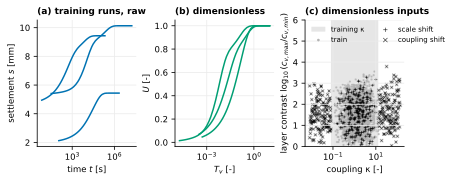

In [4]:
tr, ptr = data["train"], physics(data["train"])
Tc = ptr["H"] ** 2 / ptr["cv_eff"]                    # consolidation time
runs = [int(np.abs(Tc - np.quantile(Tc, q)).argmin()) for q in (.1, .5, .9)]
X, U, _ = represent(tr.loc[runs], "dimensionless")
fig, ax = plt.subplots(1, 3, figsize=(6.2, 2.4))
for i, tv, u in zip(runs, 10 ** X[:, 0].reshape(3, N_T), U.reshape(3, N_T)):
    ax[0].semilogx(tr.loc[i, TIMES], 1e3 * tr.loc[i, SETTLE], c=COLOR["raw"])
    ax[1].semilogx(tv, u, c=COLOR["dimensionless"])
ax[0].set(title="(a) training runs, raw", xlabel="time $t$ [s]",
          ylabel="settlement $s$ [mm]")
ax[1].set(title="(b) dimensionless", xlabel="$T_v$ [-]",
          ylabel="$U$ [-]")
ax[2].axvspan(K_MIN, K_MAX, label="training κ", **BAND)
for split, kw in {"train": dict(c="0.7", marker="."),
                  "scale shift": dict(c="k", marker="+"),
                  "coupling shift": dict(c="k", marker="x")}.items():
    p = physics(data[split])
    ax[2].scatter(p["kappa"], np.log10(p["cv"].max(1) / p["cv"].min(1)),
                  s=8, lw=0.5, label=split, rasterized=True, **kw)
ax[2].set(xscale="log", ylim=(0, 6), title="(c) dimensionless inputs",
          xlabel="coupling κ [-]",
          ylabel="layer contrast $\\log_{10}(c_{v,max}/c_{v,min})$")
ax[2].legend(loc="upper left", ncol=2, markerscale=1.5)
plt.show()

* in dimensionless form (b) the decades-wide spread in time collapses; what remains, the effect of layering and coupling, is what a model must learn
* in raw inputs both shifts are extrapolation by construction; in dimensionless inputs (c) the scale shift lies inside the training data, while the coupling shift stays outside, mainly in κ (the cv ratios or Tv also leave their range in 3 of 300 simulations)

### 2. Three Representations of the Same Data

A **feature** is an input supplied to a model and the **target** is the quantity it learns to predict; **feature transformation** changes how the same information is presented ([e-book: Feature Transformations](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_feature_transformations.html)). Here inputs and target change together:

| representation | inputs | target | back to settlement |
|---|---|---|---|
| raw | H, σ0, M, α, k1-3, Mc1-3, t (11) | s [m] | identity |
| log | log10 of each (α linear), log10 t (11) | log10 s | 10^y |
| dimensionless | log Tv, log cv,j/cv,eff, log Mc,j/Mc,eff, α, log κ (9) | U = (s − s0)/(s∞ − s0) | s0 + U (s∞ − s0) |

* each simulation becomes 41 rows, one per sampled time, with the time (t, log10 t or log10 Tv) as an input; the 41 predictions form the scored history
* dimensional analysis (Buckingham π): the equations depend only on a few dimensionless groups, so H and σ0 drop out exactly (σ0 by linearity, H into Tv)
* s0 and s∞ follow from closed-form expressions, but the path between them depends on layering and coupling and needs the simulator; the dimensionless model predicts only this progress U, so the study tests physics-based inputs and a normalized target together

### 3. Validation Design: Grouped Cross-Validation and Leakage

**Metric:** $e_i = \max_t |\hat s_i(t) - s_i(t)| \,/\, (s_{\infty,i} - s_{0,i})$, the worst error over the 41 times of simulation $i$ relative to its delayed settlement (e.g. 0.4 mm with s∞ − s0 = 8 mm gives 5%), reported as the 95th percentile (P95) over simulations; lower is better.
* the worst time counts, not the average; the denominator is small below the κ range (1-11% of s∞), which inflates every model's error there
* checks, relative to s∞ − s0, failed if any time violates them: **non-monotone**, settlement falls between adjacent times by more than 0.1%; **out of bounds**, a prediction lies more than 1% outside [s0, s∞]

**Cross-validation** trains on part of the training data and evaluates on the rest; **data leakage** is information from the validation data reaching training ([e-book: Training and Tuning](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_training_tuning.html)). Neighbouring times of one simulation are nearly identical rows, so random-row K-fold leaks; **grouped K-fold** keeps each simulation in one fold ([glossary: groups](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_glossary_a_c.html)). The neural network's (multilayer perceptron, MLP) `early_stopping` also holds out random rows, so it is off.

**Question:** does random-row K-fold measure how well a model predicts a new simulation? (random forest on raw inputs, min_samples_leaf = 1, 800 training simulations)

In [5]:
tune = data["train"].iloc[:800]                       # simulations for CV
folds = {"random-row K-fold": KFold(3, shuffle=True, random_state=SEED),
         "grouped K-fold": GroupKFold(3)}
leak = {k: scores(tune, cv_predict("random forest", {}, tune, "raw", cv))
        ["P95"] for k, cv in folds.items()}
X, y, _ = represent(tune, "raw")
X_test, _, to_s = represent(data["test"], "raw")
s_test = to_s(make_model("random forest").fit(X, y).predict(X_test))
leak["held-out test"] = scores(data["test"], s_test)["P95"]
print("P95 worst error [% of s∞ − s0]: "
      + ", ".join(f"{k} {v:.0f}%" for k, v in leak.items()))

P95 worst error [% of s∞ − s0]: random-row K-fold 40%, grouped K-fold 270%, held-out test 201%


* random-row K-fold underestimates the test error about five-fold: the forest interpolates between neighbouring times of a simulation already in the training fold
* grouped K-fold is close but pessimistic, likely because each fold trains on only two thirds of the 800 simulations

### 4. Model Tuning and Prediction Results

A **hyperparameter** is a setting chosen before fitting; each is chosen by 3-fold grouped K-fold on the 800 tuning simulations, then refitted on all 2000, never on test or shifted data ([e-book: Training and Tuning](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_training_tuning.html)):
* grids, fixed before any result: random forest (100 trees) min_samples_leaf ∈ {1, 5}; MLP (two layers of 64 ReLU units) L2 penalty α ∈ {1e-4, 1e-2} x stopping tolerance ∈ {1e-4, 1e-5}; linear regression: none
* selection by P95 on out-of-fold predictions, because the mean squared errors of s, log s and U are on different scales

**Question:** under distribution shift, which matters more, the input representation or the model? (grey line: error equal to the delayed settlement)

selected MLPs, iterations used of max_iter=500: raw 146, log 44, dimensionless 39


dimensionless MLP, κ below range: P95 15.6% of s∞ − s0, 0.6% of s∞


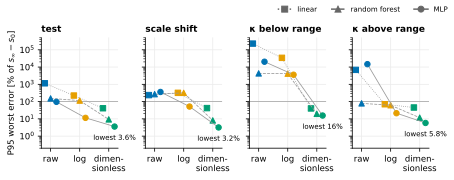

In [6]:
GRIDS = {"linear": [{}],
         "random forest": [{"min_samples_leaf": n} for n in (1, 5)],
         "MLP": [{"alpha": a, "tol": tol}
                 for a in (1e-4, 1e-2) for tol in (1e-4, 1e-5)]}
ABBR = {"min_samples_leaf": "leaf", "alpha": "α", "tol": "tol"}
rows, fitted = [], {}
for kind in KINDS:
    X, y, _ = represent(data["train"], kind)
    for name, grid in GRIDS.items():
        with warnings.catch_warnings():        # CV fits only; final fits warn
            warnings.simplefilter("ignore", ConvergenceWarning)
            cv = [scores(tune, cv_predict(name, hp, tune, kind, GroupKFold(3)))
                  ["P95"] for hp in grid]
        hp = grid[int(np.argmin(cv))]
        chosen = " ".join(f"{ABBR[k]}={v:g}".replace("e-0", "e-")
                          for k, v in hp.items())
        rows.append({"representation": kind, "model": name, "CV": min(cv),
                     "chosen": chosen or "-"})
        fitted[kind, name] = make_model(name, **hp).fit(X, y)
tuning = pd.DataFrame(rows).set_index(["representation", "model"])
print("selected MLPs, iterations used of max_iter=500: " + ", ".join(
    f"{k} {fitted[k, 'MLP'].regressor_[-1].n_iter_}" for k in KINDS))

pred, res = {}, {}
for (kind, name), model in fitted.items():
    for split in EVAL:
        X, _, to_s = represent(data[split], kind)
        pred[kind, name, split] = p = to_s(model.predict(X))
        res[kind, name, split] = scores(data[split], p)
r = res["dimensionless", "MLP", "κ below range"]
print(f"dimensionless MLP, κ below range: P95 {r['P95']:.1f}% of s∞ − s0, "
      f"{r['P95 of s_inf']:.1f}% of s∞")

fig, axes = plt.subplots(1, 4, figsize=(6.2, 2.4), sharey=True)
shift = dict(zip(MODEL, (-0.2, 0.0, 0.2)))
for ax, split in zip(axes, EVAL):
    ax.axhline(100, color="0.6", lw=0.7)
    for name, st in MODEL.items():
        x = np.arange(3) + shift[name]
        v = [res[k, name, split]["P95"] for k in KINDS]
        ax.plot(x, v, color="0.6", lw=0.8, ls=st["ls"])
        ax.scatter(x, v, c=[COLOR[k] for k in KINDS], marker=st["marker"],
                   s=30, zorder=2)
    k, n = min(fitted, key=lambda kn: res[kn + (split,)]["P95"])
    v = res[k, n, split]["P95"]
    ax.annotate(f"lowest {v:.2g}%", (KINDS.index(k) + shift[n], v), (0, -8),
                textcoords="offset points", ha="center", va="top", size=7)
    ax.set(xticks=range(3), xticklabels=["raw", "log", "dimen-\nsionless"],
           yscale="log", ylim=(0.2, 5e5), title=split)
axes[0].set_ylabel("P95 worst error [% of $s_\\infty - s_0$]")
fig.legend([plt.Line2D([], [], color="0.4", **st) for st in MODEL.values()],
           MODEL, loc="outside upper right", ncol=3)
plt.show()

* representation matters more than model: in range the best raw model (MLP, 97%) is worse than every dimensionless model, and every raw and log model fails on the scale shift (52-362%)
* below the κ range the dimensionless MLP's 15.6% is 0.6% of the total settlement s∞, because the delayed settlement there is small

### 5. Why: How Each Model Extrapolates

**Inductive bias** is the set of assumptions imposed by a model's structure, which shape its predictions where it has no data ([e-book: Linear Regression](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_linear_regression.html), [Decision Tree](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_decision_tree.html), [Ensemble Trees](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_ensemble_trees.html), [Artificial Neural Networks](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_ANN.html)):
* linear regression: one global plane, so it extrapolates linearly
* trees and forests: piecewise constant, so a prediction never leaves the range of the training targets
* ReLU neural network: piecewise linear in its input coordinates (linear in log inputs is not linear in the physical quantities), with nothing forcing physical behaviour outside the training region

(a, b) scale shift; (c) coupling shift, CV-selected model of each representation, below (< 1) and above (> 1) the κ range (dots: simulations; lines: rolling medians of 31)

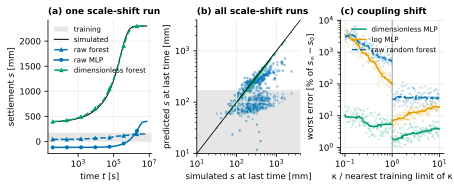

In [7]:
SHOW = {("raw", "random forest"): "raw forest", ("raw", "MLP"): "raw MLP",
        ("dimensionless", "random forest"): "dimensionless forest"}
sc = data["scale shift"]; s_sc = 1e3 * sc[SETTLE].to_numpy()
case = int(s_sc[:, -1].argmax())                     # largest scaled run
t = sc.loc[case, TIMES].to_numpy(float)
fig, ax = plt.subplots(1, 3, figsize=(6.2, 2.5))
for a in ax[:2]:                                     # training maximum [mm]
    a.axhspan(1, 1e3 * tr[SETTLE].to_numpy().max(), label="training", **BAND)
ax[0].semilogx(t, s_sc[case], color="k", lw=1, label="simulated")
for (kind, name), label in SHOW.items():
    s_hat = 1e3 * pred[kind, name, "scale shift"].reshape(-1, N_T)
    st = dict(color=COLOR[kind], marker=MODEL[name]["marker"], label=label)
    ax[0].semilogx(t, s_hat[case], ls=MODEL[name]["ls"], ms=3, markevery=6,
                   **st)
    ax[1].scatter(s_sc[:, -1], s_hat[:, -1], s=6, lw=0, alpha=0.5,
                  rasterized=True, **st)
ax[0].set(title="(a) one scale-shift run", xlabel="time $t$ [s]",
          ylabel="settlement $s$ [mm]")
ax[0].legend(loc="upper left")
ax[1].plot((10, 4000), (10, 4000), color="k", lw=0.8)
ax[1].set(xscale="log", yscale="log", xlim=(10, 4000), ylim=(10, 4000),
          title="(b) all scale-shift runs",
          xlabel="simulated $s$ at last time [mm]",
          ylabel="predicted $s$ at last time [mm]")
for kind, name in tuning.groupby(level=0)["CV"].idxmin():  # CV-selected
    for split, limit in (("κ below range", K_MIN), ("κ above range", K_MAX)):
        ratio = physics(data[split])["kappa"] / limit
        err = 100 * res[kind, name, split]["e"]
        order = np.argsort(ratio)
        med = pd.Series(err[order]).rolling(31, center=True, min_periods=10)
        ax[2].scatter(ratio, err, s=3, lw=0, color=COLOR[kind], alpha=0.3,
                      rasterized=True)
        ax[2].plot(ratio[order], med.median(), color=COLOR[kind],
                   ls=MODEL[name]["ls"],
                   label=f"{kind} {name}" if limit == K_MAX else None)
ax[2].axvline(1, color="0.5", lw=0.7)
ax[2].set(xscale="log", yscale="log", title="(c) coupling shift",
          xlabel="κ / nearest training limit of κ",
          ylabel="worst error [% of $s_\\infty - s_0$]")
ax[2].legend(loc="upper right")
plt.show()

* (a, b) the raw forest never predicts above 147 mm, inside the training range, while scale-shift runs reach 2.3 m; the dimensionless forest follows them because in dimensionless form they lie inside the training data, though a bounded target can still be wrong in U
* (c) outside the κ range the inductive bias decides: raw and log errors grow with distance below the range, while dimensionless errors stay near 5-10% below and grow slowly above

### Results

P95 worst error [% of s∞ − s0]; checks: % of the 600 out-of-range simulations that fail.

In [8]:
n = np.array([len(data[s]) for s in EVAL[1:]])
ood = lambda key, c: n @ [res[key + (s,)][c] for s in EVAL[1:]] / n.sum()
table = tuning[["chosen"]].assign(
    **{s.replace(" range", ""): [res[key + (s,)]["P95"]
                                 for key in tuning.index] for s in EVAL},
    **{f"{c} [%]": [ood(key, c) for key in tuning.index]
       for c in ("non-monotone", "out of bounds")})
table.style.format(precision=1).set_table_attributes('style="font-size:85%"')

* for these representations, models and test sets: yes for the scale shift, which dimensionless inputs and target made a familiar problem; partly for the coupling shift, which still raised the best model's error 1.6-4.3-fold; representation determines where a case lies relative to the training data, and model assumptions influence predictions outside that region
* the forest's bounded output never leaves [s0, s∞] but some histories are still non-monotone, so bounds alone do not enforce physical behaviour

### Parting Comments / Promote You

* nondimensionalise inputs and target before fitting when the governing equations are known; group cross-validation folds by simulation, experiment or well; check where a new case sits in the model's input space before trusting it
* limitations: one physics problem, small hyperparameter grids, one seed per model, P95 over 150-300 simulations per split
* I am a PhD student in Petroleum and Geosystems Engineering at UT Austin, working on coupled flow and geomechanics with fully coupled simulations in the OpenFOAM framework, especially on parent-child well fracture interactions

### Attribution

* methods and concepts follow the course e-book, cited by chapter where they are used: Pyrcz, M.J., *Applied Machine Learning in Python: a Hands-on Guide with Code* (CC BY-NC-ND 4.0); no code was copied from it
* models and cross-validation: scikit-learn
* simulator and data: a layered extension of the reference solver in [poroConsolidationFoam](https://github.com/nakulsanadhya/poroConsolidationFoam)
* Claude (Anthropic) assisted with drafting the notebook code, figures and text, and the layered solver and data-generation code.

I hope this was helpful,

*Nakul*